# Linear-probe accuracy and plant-model validation

N132 · stopped · updated 2026-11-02 19:45:30

**Primary display: independent linear-probe accuracy.** Frozen encoder, 12 refitted logistic readers, 50 support labels per reader; separate validation support100 and query7,844. Balanced accuracy weights the four day/night × city/highway cells equally. Worst-cell accuracy averages each reader's minimum cell accuracy.

| Arm | Stream progress | Probe at arrival | Balanced linear acc % | Worst-cell acc % | Gain vs full at same arrival (pp) | Balanced CE |
|---|---:|---:|---:|---:|---:|---:|
| full | 67,724 | 67,724 | **62.514** | 53.423 | +0.000 | 0.955746 |
| full_quarter | 61,952 | 61,440 | **61.837** | 54.485 | -0.505 | 1.027024 |
| fixed_sparse | pending | — | — | — | — | — |
| mpc_label_free | 67,724 | 67,724 | **60.107** | 49.874 | -2.407 | 0.760991 |
| mpc_task | 67,724 | 67,724 | **60.100** | 49.635 | -2.415 | 0.774333 |

Training progress and probe arrival are distinct: evaluation runs every4,096 arrivals. Same-arrival gains avoid comparing different training horizons.

## What the plant model actually predicts

The physical plant is the SSL encoder/decoder plus AdamW state. Its action-conditioned ridge surrogate predicts positive next-state health and optimizer summaries, plus four canary cell CEs for task MPC. It does **not** directly predict linear-probe accuracy. Validation accuracy tests the complete controller separately.

The predictor uses current/recent health, optimizer summaries and cheap current-image features. Hold is identity; ordinary and refresh/replay have separate ridge heads. Online targets mature only after copied actions are measured. A copied-state guard can reject a poor forecast, so good final task performance alone does not prove that the predictor is accurate.

Plant-model validation uses prediction error recorded BEFORE each measured outcome trains the predictor.

| Controller | Online measured actions | Periodic audit states | Audit best-action agreement | Always-hold agreement | Useful-opportunity recall |
|---|---:|---:|---:|---:|---:|
| mpc_label_free | 1,247 | 265 | 77.7% | 80.4% | 3.8% |
| mpc_task | 722 | 265 | 69.8% | 70.2% | 0.0% |

Forecast skill is measured on **log changes**, so nearly constant levels cannot make persistence look impressive. Negative skill means the predictor is worse than its baseline.

**mpc_label_free: periodic counterfactual audits**

| Output | MSE reduction vs persistence | vs frozen ridge | vs warm action mean | Change-sign accuracy |
|---|---:|---:|---:|---:|
| RankMe | +10.5% | +74.3% | +19.6% | 63.6% |
| Feature variance | +13.7% | +69.8% | +24.5% | 61.5% |
| Reconstruction loss | -364.0% | +98.1% | +96.6% | 55.3% |
| Parameter norm | +83.5% | +31.1% | +28.5% | 84.8% |
| Adam first-moment norm | +81.1% | +11.6% | +21.9% | 80.8% |
| Adam second-moment norm | +4.5% | +29.0% | +26.0% | 61.9% |
| Adam second-moment mean | +13.1% | +18.5% | +36.1% | 64.8% |
| Adam first-moment absolute mean | +85.7% | +6.6% | +19.0% | 84.5% |

Reconstruction checked against logged health, final controller state, ridge weights and observation counts. Selected-action and ordinary/replay breakdowns are saved in the diagnostic JSON.

**mpc_task: periodic counterfactual audits**

| Output | MSE reduction vs persistence | vs frozen ridge | vs warm action mean | Change-sign accuracy |
|---|---:|---:|---:|---:|
| RankMe | +20.7% | +78.7% | +24.8% | 65.1% |
| Feature variance | +18.5% | +75.7% | +18.0% | 62.6% |
| Reconstruction loss | +54.4% | +80.4% | +9.5% | 77.2% |
| Parameter norm | +85.7% | +12.2% | +27.5% | 89.4% |
| Adam first-moment norm | +71.4% | +13.7% | +62.5% | 77.9% |
| Adam second-moment norm | +8.5% | +45.1% | +4.2% | 64.0% |
| Adam second-moment mean | +11.9% | +40.1% | +8.1% | 65.5% |
| Adam first-moment absolute mean | +78.3% | +23.3% | +68.2% | 81.9% |
| Day/city CE | +16.7% | +51.1% | +35.4% | 68.1% |
| Day/highway CE | +48.3% | +50.7% | +59.0% | 77.7% |
| Night/city CE | +8.8% | +91.6% | +7.5% | 63.6% |
| Night/highway CE | +23.1% | +85.6% | +55.6% | 68.9% |

Reconstruction checked against logged health, final controller state, ridge weights and observation counts. Selected-action and ordinary/replay breakdowns are saved in the diagnostic JSON.

**Secondary chronological warm-prefix check** — fit on the first 16 warm states (32 sibling actions), test the later 16 states. This is separate from online filtered-path evidence.

| Predictor | Rank skill vs persistence | Variance skill | Reconstruction skill | First-moment norm skill |
|---|---:|---:|---:|---:|
| mpc_label_free | -19.1% | -48.3% | -73.3% | +53.9% |
| mpc_task | -19.1% | -48.3% | -73.3% | +53.9% |

One seed/order, dependent streaming observations and repeatedly consulted sensing banks. Audit results describe visited states and tested actions; they do not establish unrestricted action-value prediction, long-horizon forecasts or cross-seed reproducibility.

This observer reads saved artifacts only. It uses no GPU training and changes no controller, objective, admissions or frozen input.


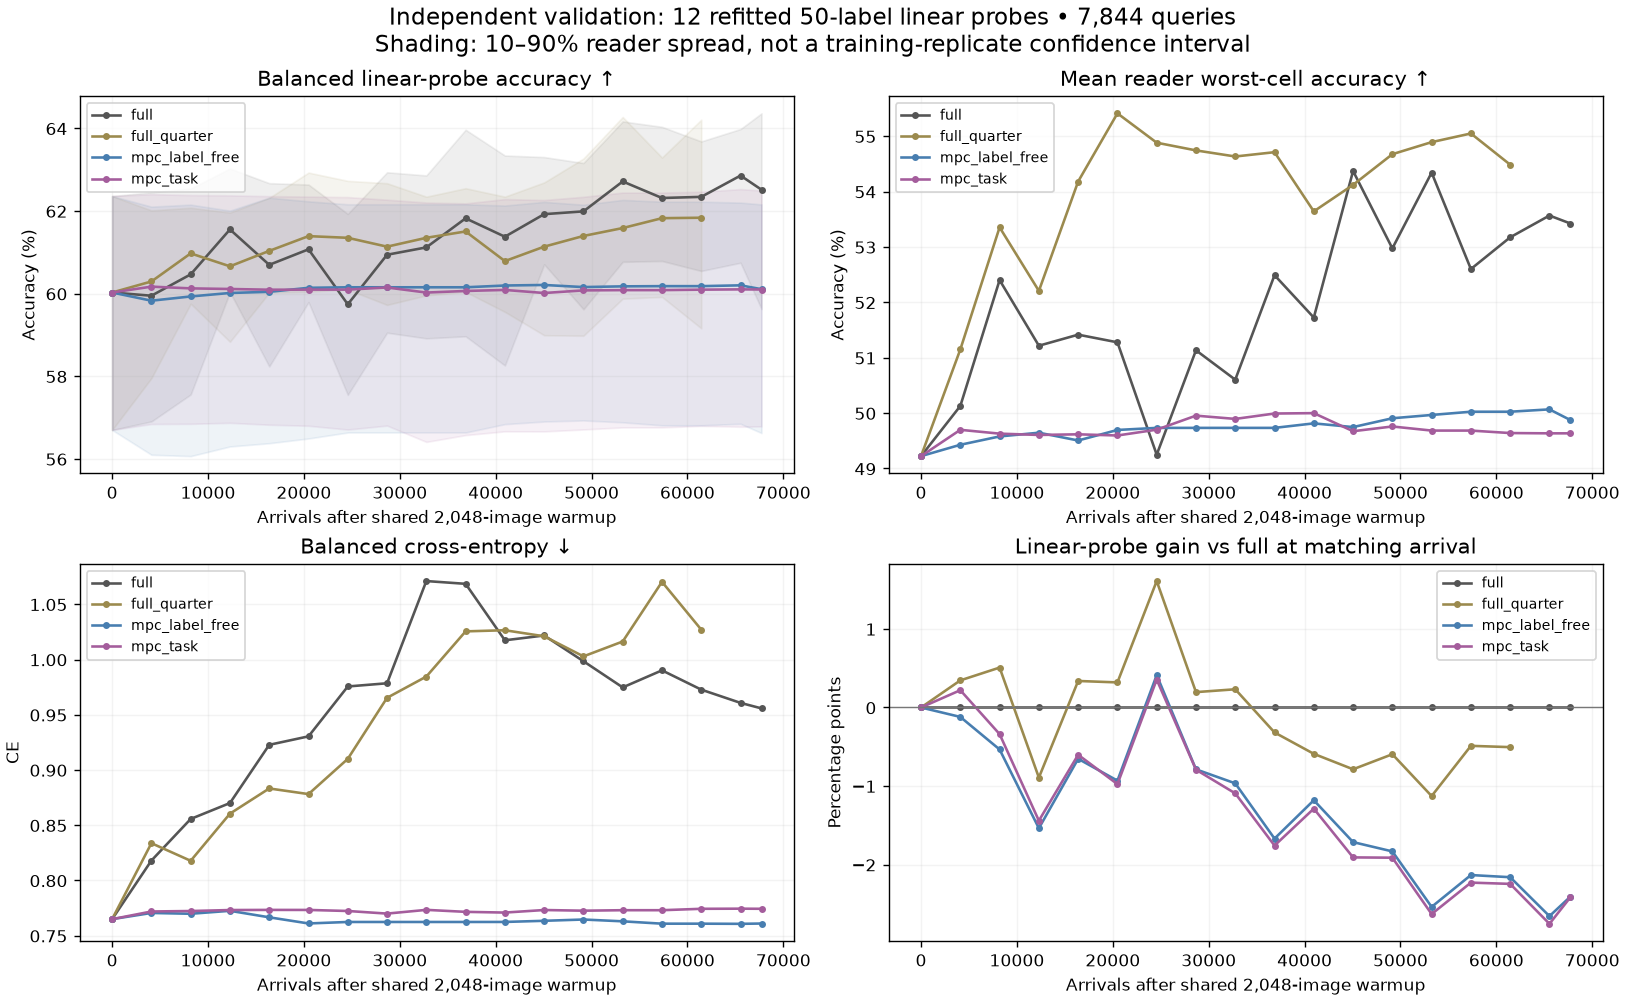

In [ ]:
from IPython.display import Image, display
display(Image(filename='C:\\CAFL-E\\project\\cafl4ds\\outputs\\evidence-mpc-bdd\\20261102-n132\\diagnostics\\linear-probe-accuracy.png'))


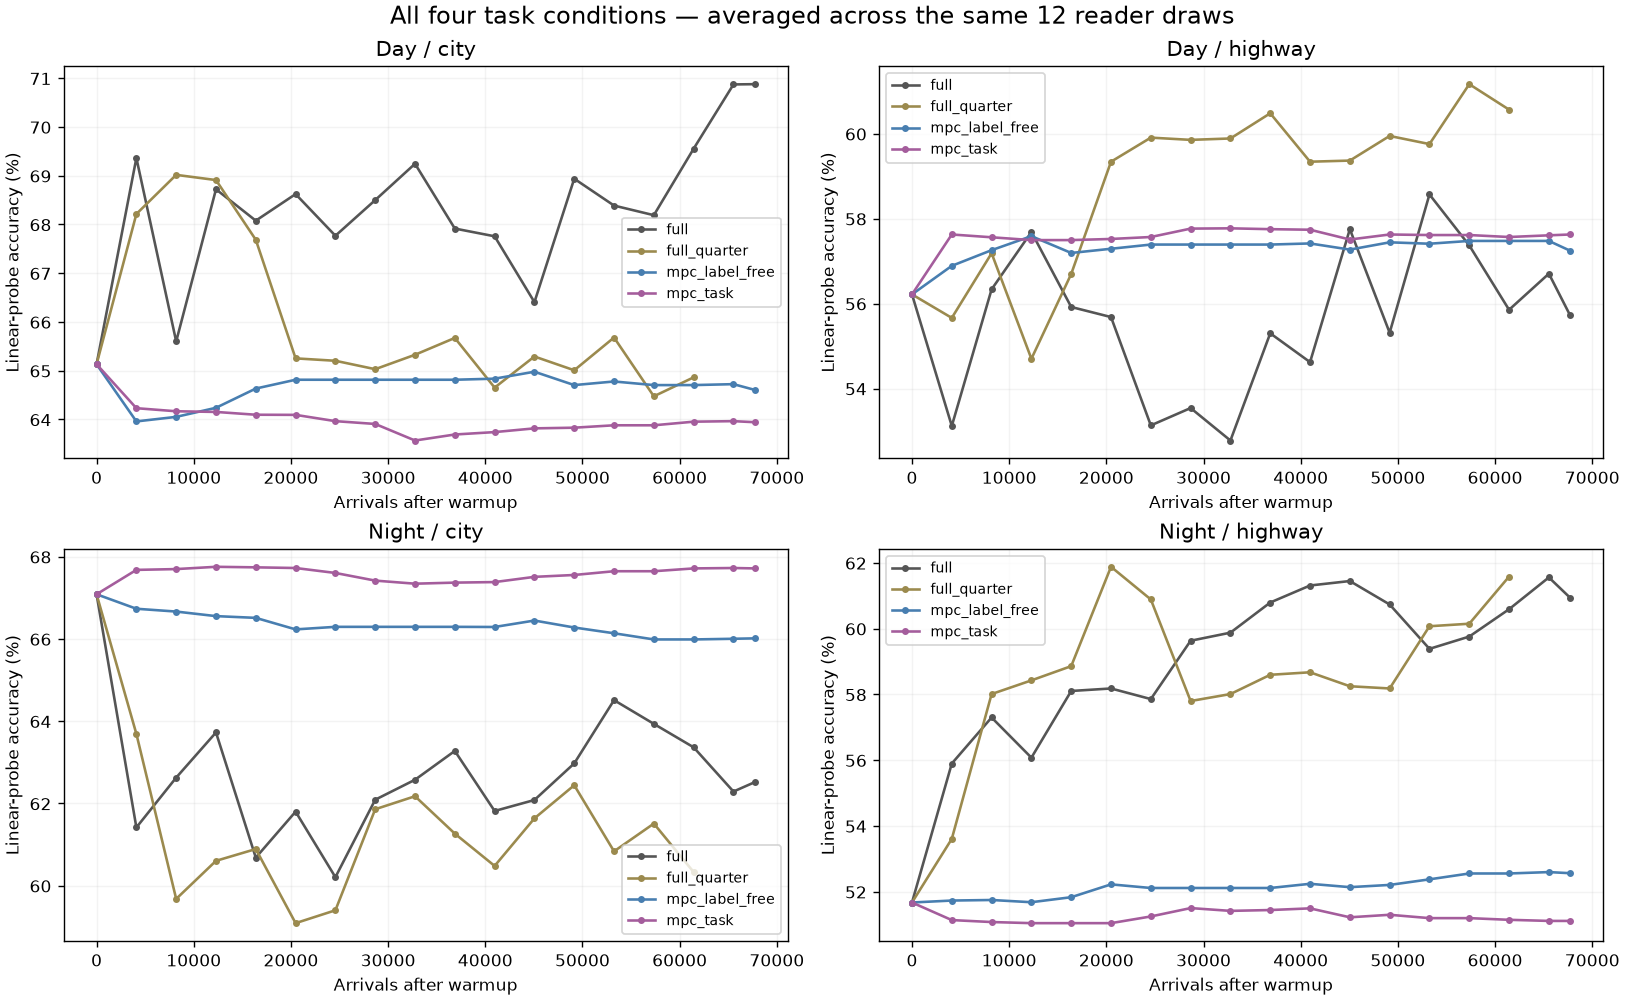

In [ ]:
from IPython.display import Image, display
display(Image(filename='C:\\CAFL-E\\project\\cafl4ds\\outputs\\evidence-mpc-bdd\\20261102-n132\\diagnostics\\condition-accuracy.png'))


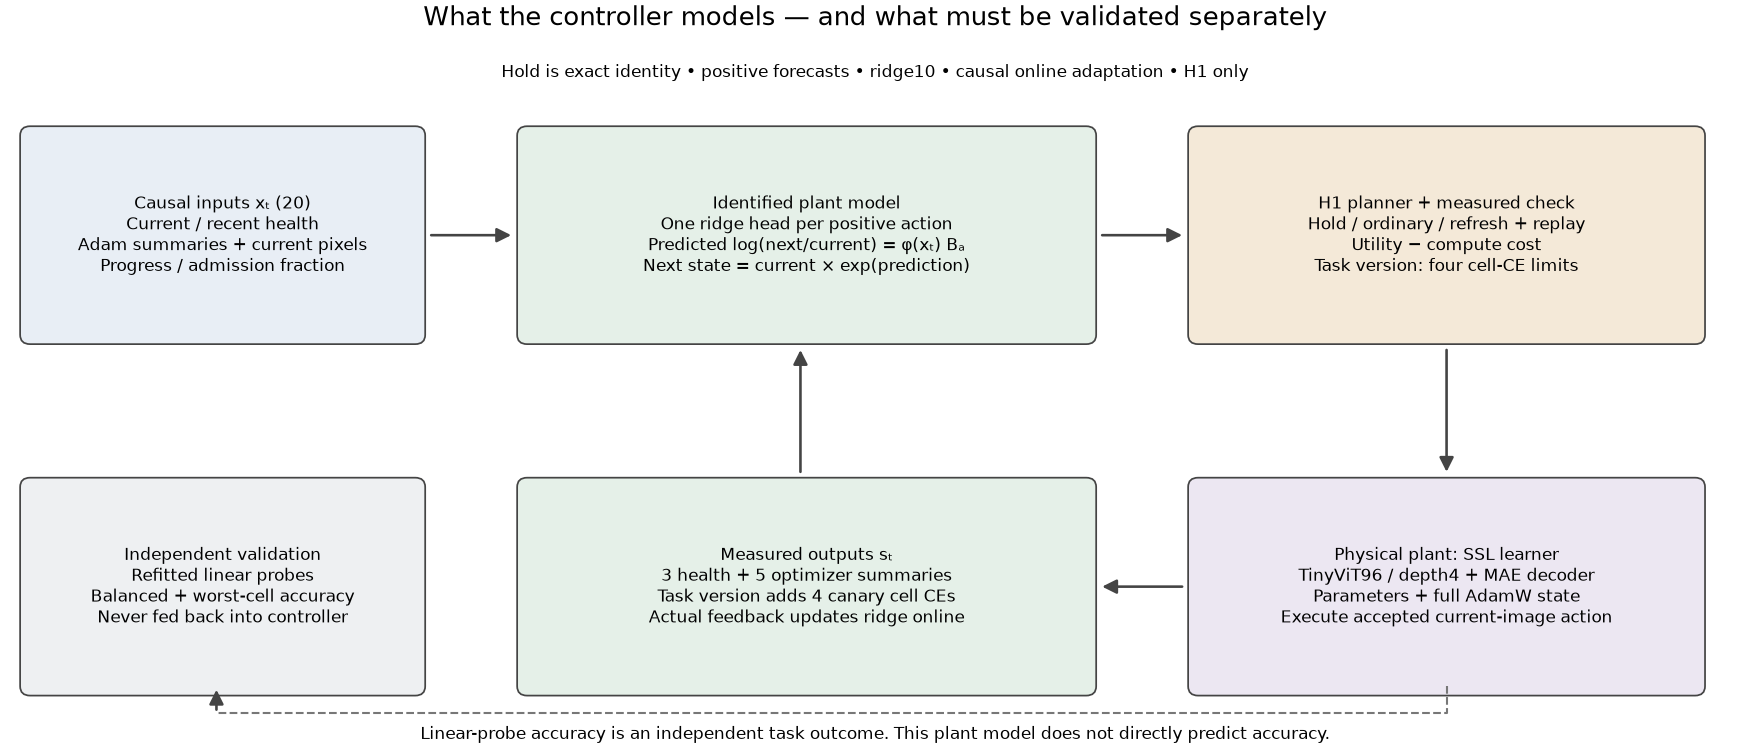

In [ ]:
from IPython.display import Image, display
display(Image(filename='C:\\CAFL-E\\project\\cafl4ds\\outputs\\evidence-mpc-bdd\\20261102-n132\\diagnostics\\plant-model.png'))


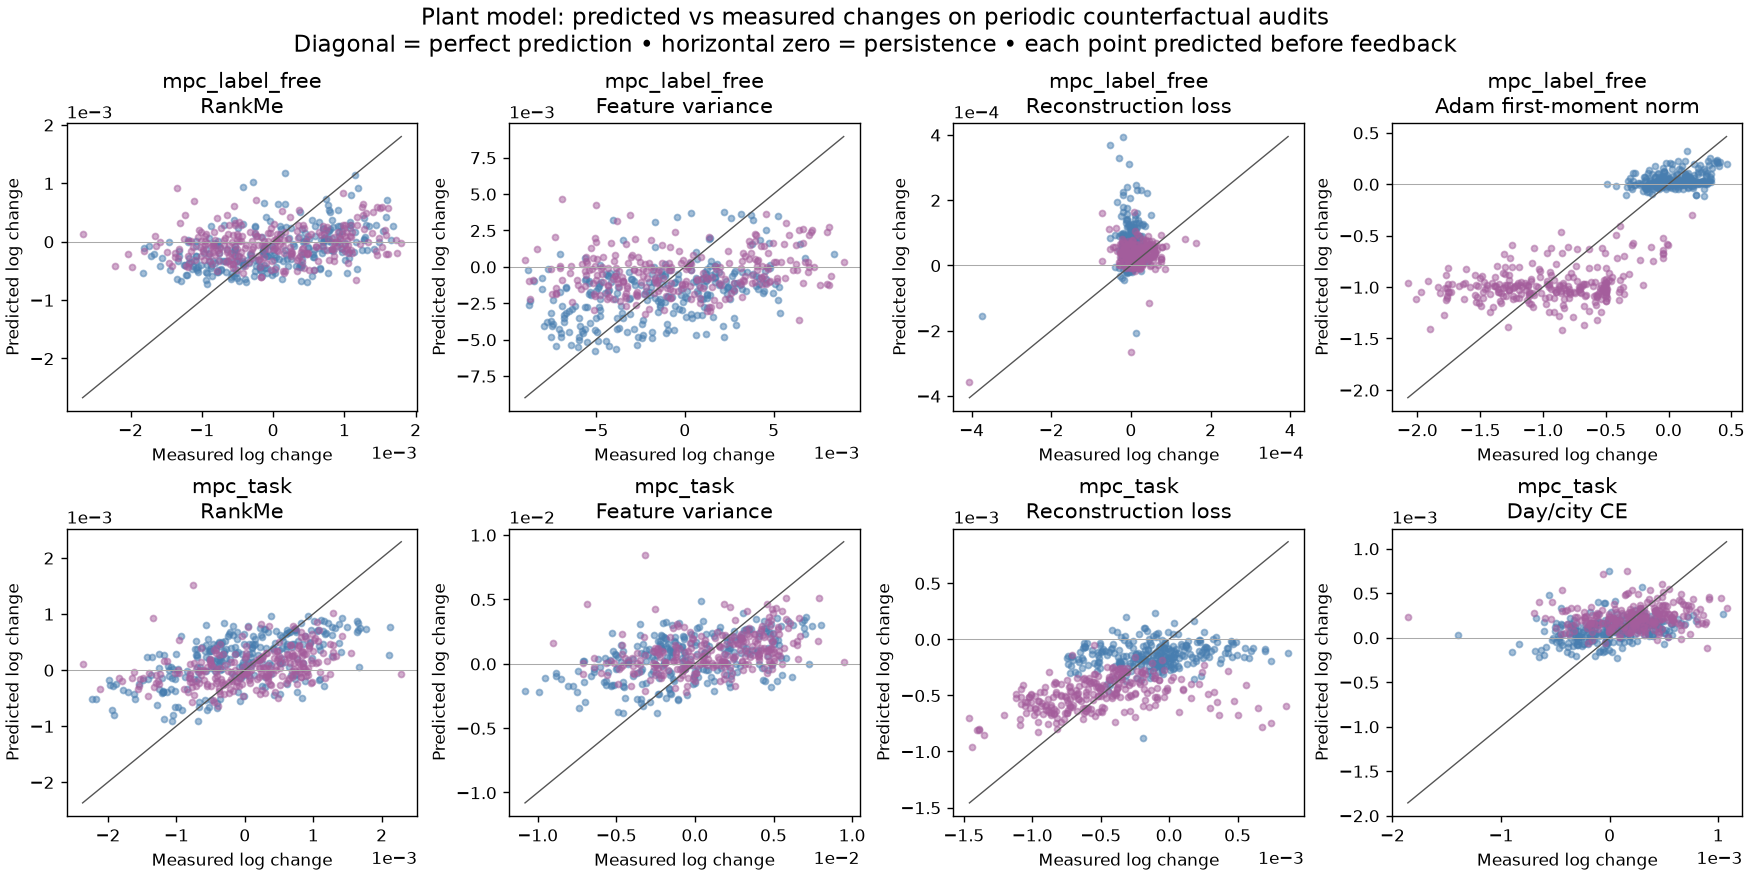

In [ ]:
from IPython.display import Image, display
display(Image(filename='C:\\CAFL-E\\project\\cafl4ds\\outputs\\evidence-mpc-bdd\\20261102-n132\\diagnostics\\plant-prediction.png'))
